# A01 · 채권–KOSPI200 상관 시각화: 국고채10년 · 단기채 vs KODEX 200

**Track A · Phase A2-①**. A00 의 데이터 계약(일간 로그수익률, `dq_trim_canonical`, 공통 1,902 거래일) 위에서
**KOSPI200 과 채권 ETF 의 상관이 시간에 따라 어떻게 바뀌는가**를 30·60·120 거래일 rolling 상관으로 본다.

| 역할 | ETF | 메모 |
|---|---|---|
| 기준 (reference) | `069500` KODEX 200 | KOSPI 200 |
| 대조 (control, 독립 증거 아님) | `102110` TIGER 200 | 같은 지수 — 결과가 브랜드·추적오차에 강건한지 |
| 장기 금리 | `148070` KIWOOM 국고채10년 | duration 김 → 금리 민감 |
| 단기 금리 | `153130` KODEX 단기채권 | 극저변동 · 0 수익률 16.8% |

**연구 질문**
1. 국고채10년–KOSPI200 상관은 안정적인가, 부호가 바뀌는가? 바뀐다면 언제·얼마나 오래?
2. 30·60·120 창은 같은 현상을 다르게 보여주는가?
3. 0선 교차는 '구조 변화'인가, 0 근처 잡음인가?
4. 단기채의 반복 0 수익률은 결과를 얼마나 왜곡하는가?

국고채5년 ETF 는 수집되지 않았으므로 다루지 않는다. 계산 함수는 모두 `src/r2h/research_a/` 에서 import 한다.

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "research_a_contract.yaml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.kfont import setup_korean_font
from src.r2h.research_a import contract as K, data as D, qa as Q
from src.r2h.research_a import rolling_correlation as RC, robustness as RB, visualization as V
from src.r2h.research_a import correlation_events as CE, price_events as PE, event_matching as EM

setup_korean_font()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 105, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

C = K.load_contract(ROOT)
VERSION = K.input_data_version(D.read_manifest(C))
REF = C.reference
SPEC = D.etf_manifest(C).set_index("ticker")
LAB = {t: f"{t} {SPEC.at[t, 'name']}" for t in SPEC.index}
FIG_DIR = ROOT / "reports" / "r2h" / "research_a" / "figures" / "A01"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    p = FIG_DIR / f"{name}.png"
    fig.savefig(p, bbox_inches="tight", dpi=110)
    return p

assert D.verify_raw_sha(C)["match"].all(), "raw sha mismatch"
r = D.returns(C, "dq_trim_canonical")      # 실제 데이터 · 일간 로그수익률(logdiff) · 261240 DQ 2일 NaN
rr = D.returns(C, "raw")                   # DQ 처리 없음 (민감도용)
close = D.load_close_panel(C)              # KRW, 20종 공통 거래일
print("ROOT:", ROOT, "| input_version:", VERSION[:16], "| sha:", K.git_sha(ROOT)[:10], "| r:", r.shape, r.index[0].date(), "~", r.index[-1].date())

ROOT: /home/sieg/projects-wsl/hongik_univ_26_2/SA/.worktrees/SA_ETF/codex-a | input_version: fd9713f7f985e950 | sha: 95b93ea846 | r: (1902, 20) 2019-01-03 ~ 2026-10-02


## 1. 가격 · 누적수익률 · 변동성 — 두 자산은 어떤 '스케일'에서 움직이는가

**선수 개념**
- 정규화 가격 $\tilde P_t = C_t / C_{t_0}$ : 시작일을 1 로 맞춰 *모양*만 비교한다 (수준 상관을 보려는 것이 아님 — A00 §3).
- 누적 로그수익률 $\sum_{s\le t} r_s = \ln(C_t/C_{t_0})$, 누적수익률 $= e^{\sum r}-1$.
- 20일 rolling 변동성 $\sigma_t^{(20)}=\mathrm{sd}(r_{t-19..t})\cdot\sqrt{252}$ (연환산). 상관을 해석할 때 **분모**가 되는 양이다.

**왜 먼저 보나.** 상관계수는 단위가 없지만, 두 자산의 변동성 차이가 100배라면 한쪽의 작은 틱 움직임이 상관을 좌우할 수 있다.

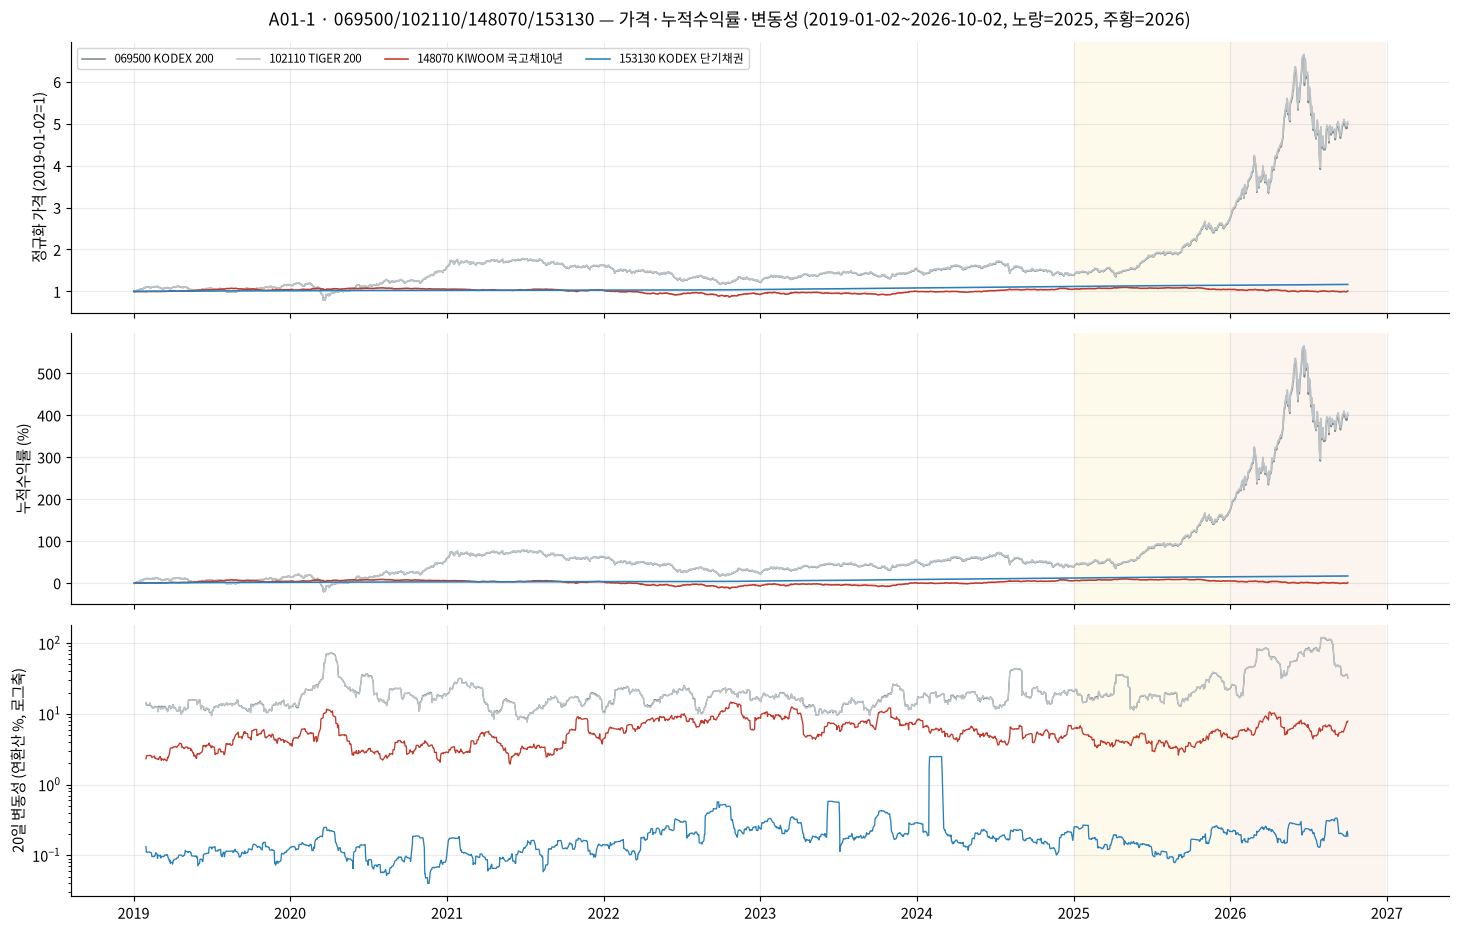

,ann_vol_full,ann_vol_2020,ann_vol_2024,ann_vol_2025,ann_vol_2026,cum_ret_full
069500 KODEX 200,0.2846,0.2940,0.2084,0.2254,0.6720,3.9969
102110 TIGER 200,0.2840,0.2905,0.2094,0.2264,0.6718,4.0477
148070 KIWOOM 국고채10년,0.0610,0.0484,0.0539,0.0429,0.0692,0.0060
153130 KODEX 단기채권,0.0032,0.0013,0.0072,0.0017,0.0022,0.1662


In [2]:
T4 = ["069500", "102110", "148070", "153130"]
ctx = RC.price_context(close, r, T4, vol_window=20)
fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for t, col in zip(T4, ["#7f8c8d", "#bdc3c7", "#c0392b", "#2980b9"]):
    ax[0].plot(ctx["norm_price"].index, ctx["norm_price"][t], color=col, lw=1.1, label=LAB[t])
    ax[1].plot(ctx["cum_ret"].index, ctx["cum_ret"][t] * 100, color=col, lw=1.1)
    ax[2].plot(ctx["vol"].index, ctx["vol"][t] * 100, color=col, lw=.9)
ax[0].set_ylabel("정규화 가격 (2019-01-02=1)"); ax[0].legend(fontsize=8, ncol=4)
ax[1].set_ylabel("누적수익률 (%)"); ax[2].set_ylabel("20일 변동성 (연환산 %, 로그축)"); ax[2].set_yscale("log")
for a in ax: V.shade_periods(a)
fig.suptitle("A01-1 · 069500/102110/148070/153130 — 가격·누적수익률·변동성 (2019-01-02~2026-10-02, 노랑=2025, 주황=2026)")
fig.tight_layout(); savefig(fig, "01_price_cum_vol"); plt.show()

vol_tab = pd.DataFrame({"ann_vol_full": r[T4].std() * np.sqrt(252),
                        **{f"ann_vol_{y}": r.loc[r.index.year == y, T4].std() * np.sqrt(252) for y in (2020, 2024, 2025, 2026)},
                        "cum_ret_full": ctx["cum_ret"][T4].iloc[-1]}).rename(index=LAB)
display(vol_tab.round(4))
v = r[T4].std() * np.sqrt(252)
assert 85 < v["069500"] / v["153130"] < 90 and 4.5 < v["069500"] / v["148070"] < 5

### 해석
- **본 것**: 연환산 변동성은 069500 28.5%, 148070 6.1%, 153130 0.32%. KOSPI200 은 국고채10년의 약 4.7배, 단기채의 약 88배 변동한다.
  2026 년에는 069500 변동성이 크게 올라간다(2019-25 대비 약 3.3배 — 기존 `etf_final_stats.csv` vol_ratio_26 와 같은 현상).
- **의미**: 153130 의 하루 움직임은 대부분 틱 단위다. 이런 시계열의 상관은 "방향이 같은가"보다 "틱이 언제 바뀌는가"에 좌우될 수 있다(§6).
- **하지 않는 해석**: 누적수익률 차이는 *성과* 비교일 뿐 관계(상관)에 대한 증거가 아니다.

> **재구성 질문** — 변동성이 88배 다른 두 자산의 상관계수가 '같은 단위'에서 비교 가능한 이유와, 그럼에도 저변동 자산의 상관이 불안정할 수 있는 이유는?

## 2. 정적 상관 — 전체 표본 하나의 숫자가 숨기는 것

**Pearson** $\rho=\dfrac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2\sum (y_i-\bar y)^2}}$ : 선형 공동변동. 큰 값 몇 개에 민감.
**Spearman** = 순위로 바꾼 뒤의 Pearson : 단조 관계, 꼬리에 덜 민감하지만 **동률(같은 값)**이 많으면 정보가 줄어든다.
순위 통계는 A1 계약대로 `rank_safe`(1e-12 반올림) 후 계산한다.

연도별로 쪼개 보면, 전체표본 상관이 여러 국면의 평균임을 알 수 있다.

,full_pearson,full_spearman,dev_2019_2024_pearson,val_2025_pearson,holdout_2026_pearson
ticker,,,,,
102110 TIGER 200,0.999,0.998,0.998,0.999,0.999
148070 KIWOOM 국고채10년,0.134,0.061,0.076,-0.029,0.369
153130 KODEX 단기채권,0.046,0.047,0.002,-0.051,0.295


,y2019,y2020,y2021,y2022,y2023,y2024,y2025,y2026
ticker,,,,,,,,
102110 TIGER 200,0.997,0.999,0.999,0.998,0.996,0.998,0.999,0.999
148070 KIWOOM 국고채10년,-0.404,0.049,0.010,0.177,0.302,-0.007,-0.029,0.369
153130 KODEX 단기채권,0.032,-0.092,0.024,-0.013,0.071,0.006,-0.051,0.295


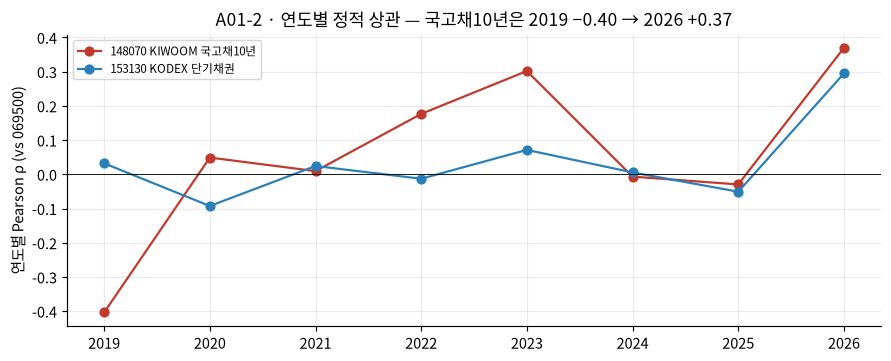

In [3]:
st = RB.static_corr_by_period(r, REF, ["102110", "148070", "153130"]).set_index("ticker")
yr = st[[c for c in st.columns if c.startswith("y")]]
display(st[["full_pearson", "full_spearman", "dev_2019_2024_pearson", "val_2025_pearson", "holdout_2026_pearson"]].rename(index=LAB).round(3))
display(yr.rename(index=LAB).round(3))
fig, ax = plt.subplots(figsize=(10, 3.6))
for t, col in (("148070", "#c0392b"), ("153130", "#2980b9")):
    ax.plot(yr.columns.str[1:].astype(int), yr.loc[t], "o-", color=col, label=LAB[t])
ax.axhline(0, c="k", lw=.6); ax.set_ylabel("연도별 Pearson ρ (vs 069500)"); ax.legend(fontsize=8)
ax.set_title("A01-2 · 연도별 정적 상관 — 국고채10년은 2019 −0.40 → 2026 +0.37"); savefig(fig, "02_yearly_corr"); plt.show()
assert abs(yr.loc["148070", "y2019"] + 0.404) < 2e-3 and abs(yr.loc["148070", "y2026"] - 0.369) < 2e-3
assert abs(st.loc["148070", "full_pearson"] - 0.134) < 2e-3 and abs(st.loc["148070", "full_spearman"] - 0.061) < 2e-3

### 해석
- **본 것**: 148070–069500 전체 Pearson 0.134, Spearman 0.061. 연도별로는 **2019 −0.40, 2020 0.05, 2021 0.01, 2022 0.18, 2023 0.30, 2024 −0.01, 2025 −0.03, 2026 0.37**.
  153130 은 2019~2025 내내 |ρ|≤0.09 이다가 2026 에만 0.30.
- **의미**: "주식–채권 상관은 음(−)이다"(헤지)는 2019 에만 맞았다. 2022~2023, 2026 은 **양(+)의 상관** — 주식과 채권이 함께 오르내리는 국면.
  전체표본 0.13 은 이런 국면들의 평균일 뿐 어느 해의 관계도 대표하지 않는다 → rolling 이 필요한 이유.
- **Pearson > Spearman (0.134 vs 0.061)**: 같은 방향의 *큰* 움직임 소수가 Pearson 을 끌어올린다(예: 2026 대형 변동일). 꼬리 의존 가능성.
- **한계**: 연도 경계는 임의적이다. 2026 은 기존 EDA 가 이미 본 데이터라 독립 검증 구간(blind holdout)이 아니다.

> **재구성 질문** — 전체표본 ρ=0.13 이 "약한 양의 관계"라는 해석이 왜 틀릴 수 있는가? 연도별 값으로 설명하라.

## 3. Rolling 상관 — 정의, 시점, NaN 규칙

**정의**: 창 길이 $w$ 의 rolling 상관
$$\rho_t^{(w)} = \mathrm{corr}\big(\{x_s\}_{s=t-w+1}^{t},\ \{y_s\}_{s=t-w+1}^{t}\big)$$
- **관측 가능 시점**: $t$ 일 종가 이후 (`available_at = t`). 미래 수익률은 쓰지 않는다 (테스트 `test_rolling_no_lookahead`).
- **유효 관측**: 두 시계열이 모두 있는 날만(pairwise complete). $n_{\text{eff}} < \lceil 0.9w \rceil$ 이면 NaN.
  완전창(1.0w) 규칙이면 261240 DQ 2일 NaN 이 그 날을 포함하는 모든 창을 지운다 → 0.9 채택, 완전창은 민감도(`min_periods_sensitivity.csv`: 공통 구간 차이 0).
- **분모 0**(창 안 한쪽이 상수)이면 NaN + `const=True`. **0 으로 대체하지 않는다.**
- **Spearman rolling**: 각 창 *안에서* 순위를 매긴다. 전체표본 순위를 쓰면 미래 정보가 섞인다.

**직관적 예시 (SAMPLE)**: 같은 두 시계열이라도 창이 짧으면 표본오차가 크다. 독립·정규 가정에서 표본상관의 표준오차는 약 $1/\sqrt{w}$ →
95% 근사 오차대 $\pm1.96/\sqrt{w}$ = ±0.36(30일), ±0.25(60일), ±0.18(120일). 이것은 **근사 오차대**이지 정식 독립성 검정이 아니다
(겹치는 창은 서로 독립이 아니고, 수익률 꼬리가 두꺼우면 실제 오차는 더 크다).

In [4]:
# SAMPLE: 진짜 상관 0 인 독립 정규 쌍에서 rolling ρ 가 오차대 안에 머무는 비율
rng = np.random.default_rng(20261011)
idx = pd.bdate_range("2019-01-02", periods=1902)
xs, ys = pd.Series(rng.normal(size=1902), idx), pd.Series(rng.normal(size=1902), idx)
sim = {w: RC.rolling_corr(xs, ys, w)["rho"] for w in (30, 60, 120)}
tab = pd.DataFrame({w: {"null_band": RC.null_band(w), "share_within": RC.time_near_zero(s, RC.null_band(w)),
                        "n_zero_cross": len(RC.zero_crossings(s))} for w, s in sim.items()}).T
display(tab.round(3))
assert (tab["share_within"] > 0.9).all()

,null_band,share_within,n_zero_cross
30,0.358,0.988,201.0
60,0.253,0.972,101.0
120,0.179,0.955,76.0


**SAMPLE 해석**: 상관이 정확히 0 인 독립 쌍도 rolling ρ 는 0 선을 **수십 번** 넘는다(위 표 `n_zero_cross`). 시간의 약 95% 는 ±1.96/√w 안.
→ 실제 데이터에서 0선 교차가 많다는 사실만으로는 "구조 변화가 많다"고 말할 수 없다. 이것이 §5 지속성 규칙의 출발점이다.

## 4. 30 · 60 · 120 일 rolling 상관 — 같은 시간축 비교

아래 그림은 한 자산쌍마다 **가격·수익률·변동성·rolling ρ** 를 같은 x 축에 놓는다 (`visualization.pair_overview`).
회색 띠 = 60일 창 근사 오차대 ±0.25.

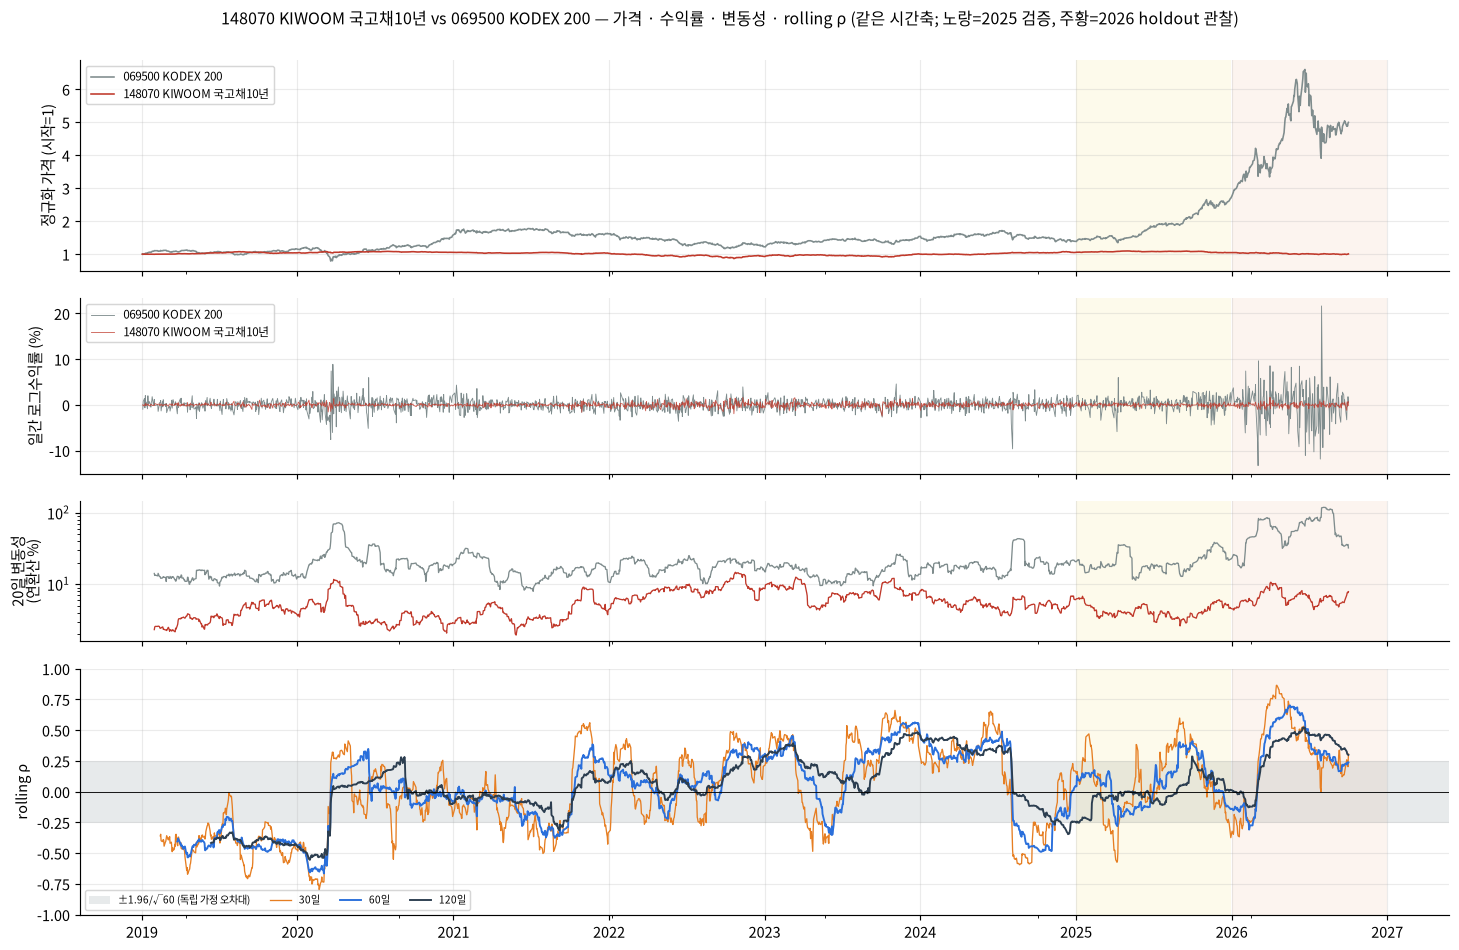

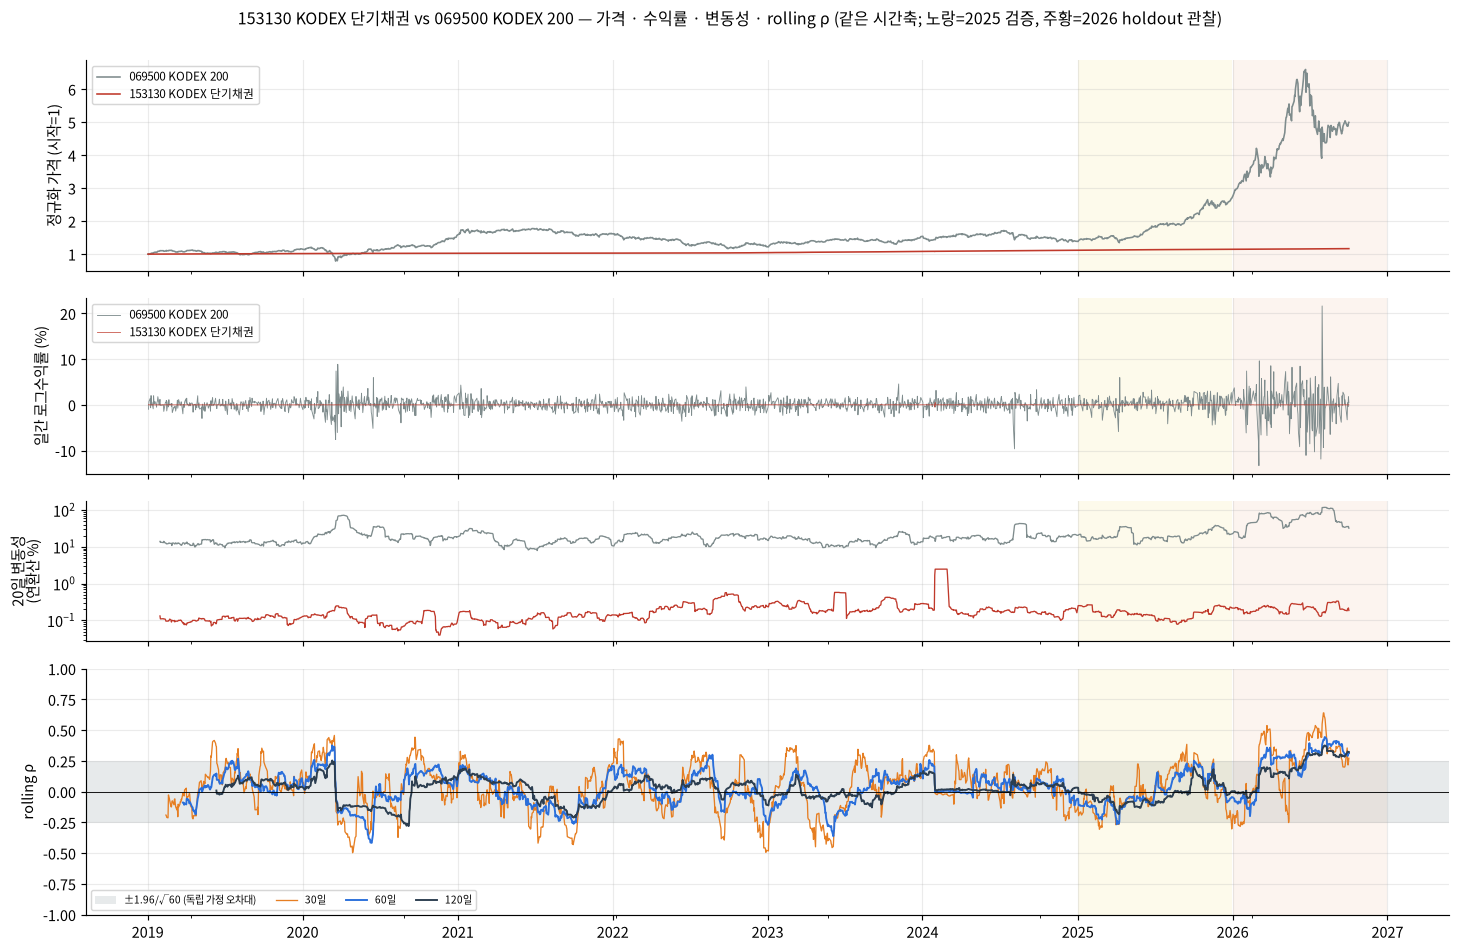

/tmp/ipykernel_70737/3010777925.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(show.round(3))


,ticker,window,method,mean,sd,min,min_at,max,max_at,share_pos,share_within_null_band,n_zero_cross,n_regime_b0.1_k10,mean_dev_2019_2024,mean_val_2025,mean_holdout_2026
0,148070,30,pearson,0.019,0.346,-0.797,2020-02-21,0.866,2026-04-17,0.499,0.642,55,21,-0.024,0.067,0.301
1,148070,30,spearman,0.003,0.325,-0.785,2020-02-21,0.831,2026-04-08,0.489,0.678,75,17,-0.044,0.062,0.288
2,148070,60,pearson,0.037,0.300,-0.664,2020-03-03,0.702,2026-05-18,0.550,0.512,45,13,-0.002,0.063,0.300
3,148070,60,spearman,0.016,0.278,-0.642,2020-02-26,0.696,2026-05-18,0.514,0.584,43,13,-0.025,0.062,0.278
4,148070,120,pearson,0.054,0.250,-0.554,2020-01-30,0.521,2026-06-17,0.541,0.539,41,7,0.031,-0.007,0.307
5,148070,120,spearman,0.027,0.234,-0.561,2020-02-24,0.502,2026-08-10,0.516,0.596,45,3,-0.001,0.015,0.255
6,148070,250,pearson,0.078,0.185,-0.498,2020-03-03,0.415,2026-06-15,0.591,0.530,23,5,0.079,-0.053,0.245
7,148070,250,spearman,0.032,0.187,-0.496,2020-03-03,0.354,2024-06-19,0.523,0.468,23,1,0.018,0.001,0.165
8,153130,30,pearson,0.045,0.199,-0.496,2020-04-28,0.641,2026-08-03,0.574,0.913,137,13,0.028,0.008,0.225
9,153130,30,spearman,0.046,0.194,-0.528,2021-09-28,0.593,2026-07-16,0.580,0.901,201,13,0.032,0.025,0.185


In [5]:
rhos = {t: {w: RC.rolling_corr(r[t], r[REF], w, min_periods=int(np.ceil(.9 * w)))["rho"] for w in (30, 60, 120)} for t in ["148070", "153130", "102110"]}
for t in ["148070", "153130"]:
    fig = V.pair_overview(close, r, REF, t, rhos[t], LAB); savefig(fig, f"03_overview_{t}"); plt.show()
ws = RB.window_summary(r, REF, ["148070", "153130"], (30, 60, 120, 250), ("pearson", "spearman"))
show = ws[["ticker", "window", "method", "mean", "sd", "min", "min_at", "max", "max_at", "share_pos", "share_within_null_band",
           "n_zero_cross", "n_regime_b0.1_k10", "mean_dev_2019_2024", "mean_val_2025", "mean_holdout_2026"]]
display(show.round(3))
p = ws[ws.method == "pearson"].set_index(["ticker", "window"])
assert abs(p.loc[("148070", 60), "mean"] - 0.037) < 2e-3 and p.loc[("148070", 60), "n_zero_cross"] == 45
assert abs(p.loc[("148070", 60), "share_within_null_band"] - 0.512) < 5e-3 and p.loc[("153130", 30), "n_zero_cross"] == 137

### 해석
- **148070 (국고채10년)**: 60일 ρ 평균 **0.037**, 표준편차 0.30, 범위 −0.66(2020-03-03) ~ 0.70(2026-05-18). 시간의 **51%** 를 ±0.25 오차대 안에서 보낸다.
  기간 평균은 2019-24 −0.00 → 2025 0.06 → 2026 **0.30**. 2020-02~03(코로나 초기) 강한 음(−), 2026 강한 양(+).
- **창 효과**: 30일은 평균 0.019·sd 0.35 로 진동이 크고, 120일은 평균 0.054·sd 0.25 로 매끈하다. 교차 수는 55(30일) → 45(60일) → 41(120일) 로 줄지만
  120일에서도 41번이다 — 장기창도 0 근처에서는 자주 넘는다. 250일(기존 분석 창)에서는 23번.
- **153130 (단기채)**: 시간의 **90%** 가 오차대 안. 30일 창에서 0선 교차 **137번**. 평균 0.045 — 사실상 '관계 없음' 위의 잡음으로 보는 것이 데이터와 맞다.
- **하지 않는 해석**: 120일 그림의 매끈한 곡선을 '더 정확한 관계'로 읽으면 안 된다 — 긴 창은 변화를 *늦게*, *평균해서* 보여준다(§5 확정 지연).

> **재구성 질문** — 30일과 120일 창이 같은 2020-03 충격에 서로 다른 시점에 반응하는 이유를 창 정의로 설명하라.

## 5. 0선 교차와 지속성 — 후보(candidate)와 확정(confirmed)을 분리한다

**정의**
- **C1 0선 교차**: $\mathrm{sign}(\rho_t)\ne\mathrm{sign}(\rho_{t-1})$. 가장 단순하고 잡음에 가장 민감.
- **C3 부호 전환 (히스테리시스)**: $|\rho|>b$ 가 같은 부호로 $k$ 거래일 연속이면 그 부호 상태로 '확정'.
  - `candidate_at` = 그 run 의 첫날 (band 밖으로 나간 날)
  - `confirmed_at` = k 번째 날 → 이때 비로소 "지속됐다"를 안다. **candidate_at 시점에는 미래 정보**가 필요하다.
  - primary $b=0.1,\ k=10$ (contract), 민감도 $b\in\{0,0.1,0.2,\pm1.96/\sqrt w\},\ k\in\{5,10,20\}$.
- 직관: band 는 "0 근처 잡음은 무시", persist 는 "한두 날 튄 것은 무시".

In [6]:
rows = []
for t in ["148070", "153130"]:
    for w in (30, 60, 120):
        cs = RC.crossing_summary(rhos[t][w], [RC.RegimeRule(0, 5), RC.RegimeRule(.1, 10), RC.RegimeRule(.2, 10), RC.RegimeRule(.1, 20),
                                              RC.RegimeRule(round(RC.null_band(w), 3), 10)])
        rows.append(cs.assign(ticker=t, window=w))
cnt = pd.concat(rows).pivot_table(index=["ticker", "window"], columns="rule", values="n_events")
display(cnt)
sr = RC.sign_regimes(rhos["148070"][60], RC.RegimeRule(.1, 10))
display(sr[~sr.is_initial][["candidate_at", "zero_cross_at", "confirmed_at", "from_sign", "to_sign", "prev_peak_abs", "confirm_lag_days"]].round({"prev_peak_abs": 3}))
assert cnt.loc[("148070", 60), "raw_zero_cross"] == 45 and cnt.loc[("148070", 60), "b0.100_k10"] == 13
assert cnt.loc[("148070", 60), "b0.253_k10"] == 7 and cnt.loc[("153130", 30), "b0.358_k10"] == 2 and cnt.loc[("148070", 60), "b0.200_k10"] == 9
assert (sr.loc[~sr.is_initial, "confirm_lag_days"] == 9).all()

rule           b0.000_k5  b0.100_k10  b0.100_k20  b0.179_k10  b0.200_k10  b0.253_k10  b0.358_k10  raw_zero_cross
ticker window                                                                                                   
148070 30           31.0        21.0        11.0         NaN        15.0         NaN         3.0            55.0
       60           15.0        13.0        11.0         NaN         9.0         7.0         NaN            45.0
       120          15.0         7.0         5.0         5.0         5.0         NaN         NaN            41.0
153130 30           47.0        13.0        12.0         NaN        12.0         NaN         2.0           137.0
       60           23.0        11.0         8.0         NaN         4.0         2.0         NaN            71.0
       120          23.0         6.0         4.0         2.0         2.0         NaN         NaN            46.0

,candidate_at,zero_cross_at,confirmed_at,from_sign,to_sign,prev_peak_abs,confirm_lag_days
1,2020-03-23,2020-03-19,2020-04-03,-1,1,0.664,9
2,2021-05-26,2021-05-26,2021-06-08,1,-1,0.348,9
3,2021-10-14,2021-10-12,2021-10-27,-1,1,0.375,9
4,2022-04-29,2022-04-25,2022-05-13,1,-1,0.385,9
5,2022-08-08,2022-06-08,2022-08-22,-1,1,0.221,9
6,2023-05-15,2023-05-03,2023-05-26,1,-1,0.452,9
7,2023-07-20,2023-07-10,2023-08-02,-1,1,0.350,9
8,2024-08-05,2024-08-05,2024-08-19,1,-1,0.564,9
9,2025-01-13,2024-12-23,2025-01-24,-1,1,0.489,9
10,2025-03-31,2025-03-25,2025-04-11,1,-1,0.176,9


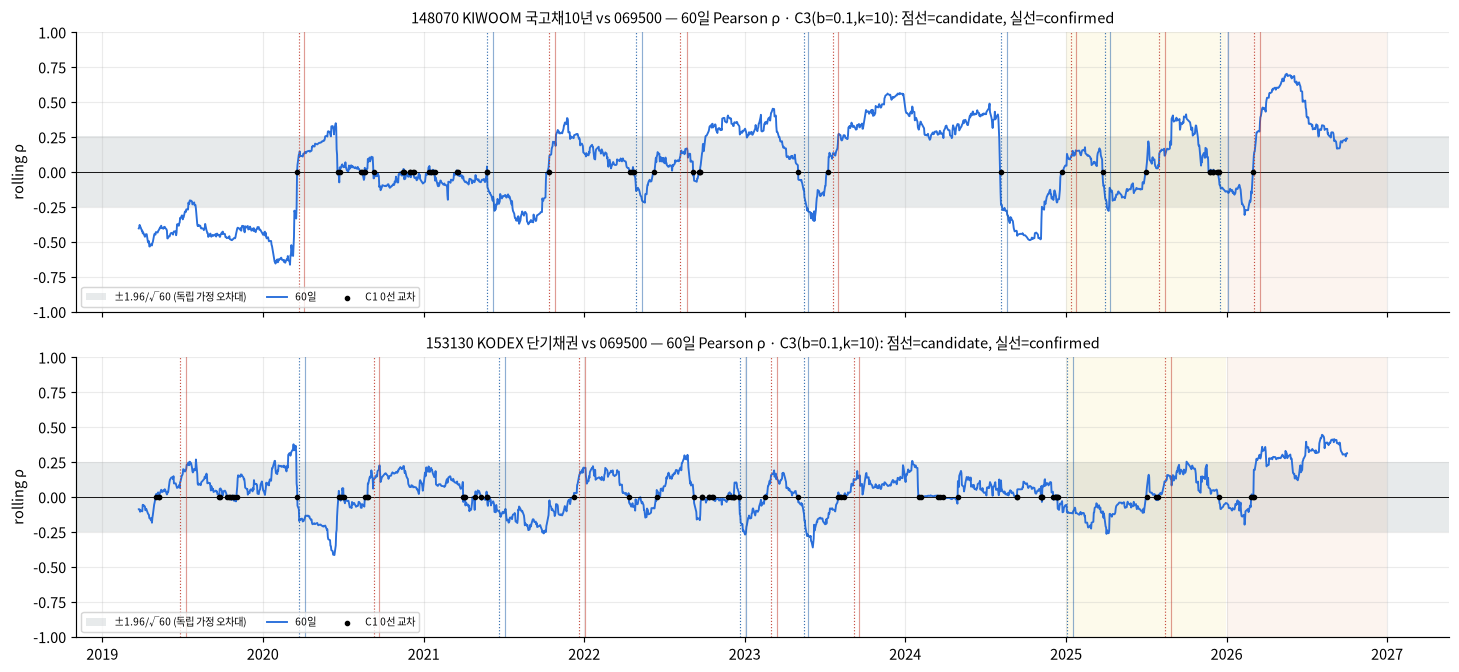

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
for a, t in zip(ax, ["148070", "153130"]):
    ev = CE.c3_sign_regime(rhos[t][60], RC.RegimeRule(.1, 10), series_id=t, reference_series_id=REF, window=60, method="pearson")
    V.rho_panel(a, {60: rhos[t][60]}, title=f"{LAB[t]} vs 069500 — 60일 Pearson ρ · C3(b=0.1,k=10): 점선=candidate, 실선=confirmed",
                band_window=60, events=ev)
    zc = RC.zero_crossings(rhos[t][60])
    a.scatter(zc.candidate_at, np.zeros(len(zc)), s=8, c="k", zorder=4, label="C1 0선 교차")
    V.shade_periods(a); a.legend(fontsize=7, loc="lower left", ncol=4)
fig.tight_layout(); savefig(fig, "04_crossings_regimes_w60"); plt.show()

### 해석
- **본 것 (148070, 60일)**: 0선 교차 45번 → C3(b=0.1, k=10) 확정 전환 **13번** (초기 상태 제외). band 0.2 면 9번, 근사 오차대(±0.25) 기준이면 7번.
  확정까지 항상 9 거래일(k−1) — 정의상 지연이다. 전환은 2020-03(− → +), 2021-05, 2021-10, 2022-04/08, 2023-05/07, 2024-08, 2025-01/03/08, 2025-12, 2026-03.
- **153130 (30일)**: 교차 137번 → C3(b=0.1,k=10) 13번, 근사 오차대(±0.36, k=10) 기준 2번. 교차의 대부분이 band 안 진동이다.
- **의미**: "교차 횟수"는 잡음 수준과 창 길이의 함수이지 구조 변화의 강도가 아니다. 지속성·크기 조건을 거친 C3 만 후보로 남긴다.
- **한계**: band·persist 값 자체가 선택이다 → A02 에서 규칙별로 결과가 어떻게 바뀌는지 검정한다. 확정 시점 기준(`confirmed_at`)으로는
  사건을 최대 9일 늦게 알 수 있을 뿐이다.

> **재구성 질문** — persistence 조건을 추가하면 왜 최초 발견 시점과 확인 시점이 달라지는가? 그 차이가 '실시간 신호'에 주는 의미는?

## 6. 같은 날 수익률 하나가 교차를 만드는가 — 진입일 영향

$\rho_t$ 와 $\rho_{t-1}$ 은 창 하나가 들어오고(t) 하나가 나가는(t−w) 차이다. 오늘만 뺀 상관
$\rho_t^{(-t)}=\mathrm{corr}(t-w+1..t-1)$ 를 계산해, $\mathrm{sign}(\rho_t^{(-t)})=\mathrm{sign}(\rho_{t-1})$ 이면
**그 교차는 오늘의 수익률 1개가 만든 것**(entering-day driven)이다. 큰 가격 변동일에 상관이 '바뀌는' 것은 이런 기계적 효과일 수 있다.

In [8]:
drv = []
for t in ["148070", "153130"]:
    for w in (30, 60, 120):
        zc = RC.zero_crossings(rhos[t][w])
        cd = RB.classify_crossing_drivers(r[t], r[REF], w, zc.candidate_at)
        drv.append({"ticker": t, "window": w, "n_cross": len(cd), "share_entering_day_driven": cd.entering_day_driven.mean(),
                    "median_abs_ret_ref_on_driven": cd.loc[cd.entering_day_driven, "abs_ret_ref"].median(),
                    "median_abs_ret_ref_on_other": cd.loc[~cd.entering_day_driven, "abs_ret_ref"].median()})
drv = pd.DataFrame(drv); display(drv.round(4))
dd = drv.set_index(["ticker", "window"])
assert abs(dd.loc[("148070", 60), "share_entering_day_driven"] - 0.444) < 5e-3
assert (dd.median_abs_ret_ref_on_driven > 1.5 * dd.median_abs_ret_ref_on_other).all()

,ticker,window,n_cross,share_entering_day_driven,median_abs_ret_ref_on_driven,median_abs_ret_ref_on_other
0,148070,30,55,0.5091,0.0155,0.0076
1,148070,60,45,0.4444,0.0159,0.0093
2,148070,120,41,0.3902,0.0156,0.0068
3,153130,30,137,0.4745,0.0146,0.0070
4,153130,60,71,0.4648,0.0145,0.0065
5,153130,120,46,0.5652,0.0161,0.0058


### 해석
- **본 것**: 148070 60일 교차의 **44%**, 153130 30일 교차의 47% 는 그날 들어온 하루 수익률을 빼면 사라진다.
  그런 날의 069500 |r| 중앙값은 1.5~1.6% 로, 다른 교차일(0.6~0.9%)의 약 2배다 — 큰 수익률일수록 창 안 공분산을 혼자 바꾼다.
- **의미**: 같은 날의 "상관 변화 + 가격 급변"은 상당 부분 **같은 관측치 하나를 두 번 센 것**이다. A02 에서 사건 매칭을 할 때 이 기계적 성분을 따로 제거해 검정한다.

> **재구성 질문** — 120일 창에서도 진입일 주도 교차가 줄지 않는 이유는? (힌트: 교차 직전 ρ 가 이미 0 에 얼마나 가까웠는가)

## 7. 단기채의 반복 0 수익률 — 분리해야 할 네 가지

153130 의 교차를 다음으로 분리한다.
1. **진짜 부호 전환** — C3 (band·persist 통과)
2. **0 근처 진동** — band 안 교차
3. **동률·순위 처리의 영향** — Pearson vs Spearman, 반올림 정책
4. **데이터 품질의 영향** — spike_reversal_candidate 2024-01-30·31

0 수익률을 NaN 으로 둔 변형은 **날짜 index 를 그대로 두고** 그 날만 결측 처리한다 (창의 달력 길이는 같고 유효 관측 $n_{\text{eff}}$ 만 준다; min_periods 0.5w).

In [9]:
zd = RB.zero_return_diagnostics(r, REF, "153130"); display(zd.round(3))
rp = RB.rank_policy_sensitivity(r, D.returns(C, "dq_trim_canonical", formula="logratio"), REF, ["153130"]); display(rp)
spk = RB.rolling_variant_diff(r, RB.mask_days(r, {"153130": ["2024-01-30", "2024-01-31"]}), REF, "153130"); display(spk.round(3))
z = zd.set_index("window")
assert z.loc[30, "n_cross_pearson"] == 137 and z.loc[30, "n_cross_pearson_zero_as_nan"] == 97 and z.loc[30, "n_cross_spearman"] == 201
assert z["index_preserved"].all() and abs(z.loc[30, "n_eff_mean_zero_as_nan"] - 25.0) < 0.1
assert rp["max_abs_round_vs_unround"].max() == 0 and spk.set_index("window").loc[30, "max_abs_diff"] > 0.3

,ticker,window,share_zero_mean_in_window,share_zero_max_in_window,spearman_corr_zero_share_vs_abs_rho,n_cross_pearson,n_cross_spearman,n_cross_pearson_zero_as_nan,mean_abs_diff_pearson_spearman,n_sign_disagree_pearson_spearman,n_valid,n_valid_zero_as_nan,n_eff_mean_zero_as_nan,n_eff_min_zero_as_nan,index_preserved
0,153130,30,0.168,0.533,-0.055,137,201,97,0.073,296,1876,1871,25.006,15,True
1,153130,60,0.169,0.467,0.125,71,110,71,0.058,273,1849,1867,49.762,30,True
2,153130,120,0.169,0.442,0.338,46,60,37,0.042,189,1795,1832,99.225,60,True


,ticker,window,max_abs_round_vs_unround,max_abs_formula_unrounded,n_sign_flip_formula_unrounded,n_sign_flip_round
0,153130,30,0.0,0.0,0,0
1,153130,60,0.0,0.0,0,0
2,153130,120,0.0,0.0,0,0


/tmp/ipykernel_70737/852443219.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  spk = RB.rolling_variant_diff(r, RB.mask_days(r, {"153130": ["2024-01-30", "2024-01-31"]}), REF, "153130"); display(spk.round(3))


,ticker,window,method,max_abs_diff,max_abs_diff_at,n_days_diff_gt_tol,first_affected,last_affected,n_sign_disagree,n_nan_a,n_nan_b,n_zero_cross_a,n_zero_cross_b
0,153130,30,pearson,0.320,2024-02-01,31,2024-01-30,2024-03-15,30,26,26,137,135
1,153130,60,pearson,0.248,2024-02-01,61,2024-01-30,2024-04-29,30,53,53,71,65
2,153130,120,pearson,0.172,2024-03-28,121,2024-01-30,2024-07-26,17,107,107,46,42


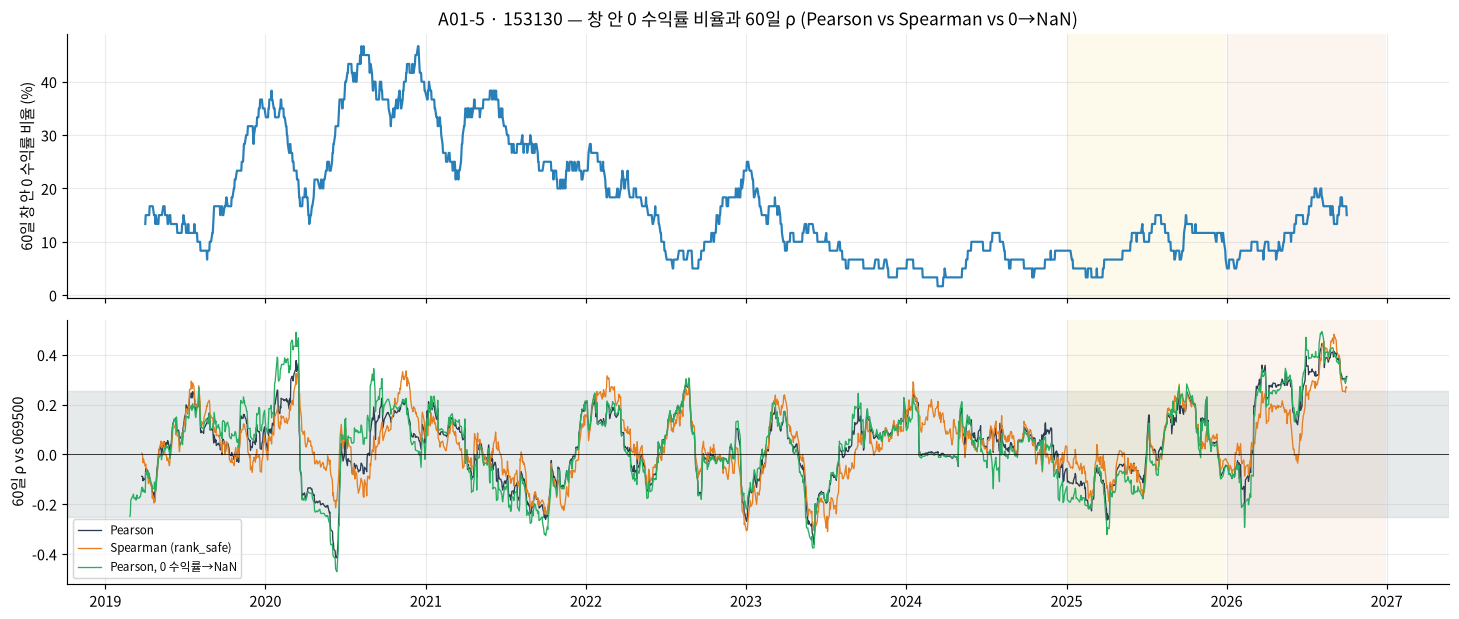

In [10]:
zshare = (r["153130"] == 0).astype(float).rolling(60).mean()
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(zshare.index, zshare * 100, color="#2980b9"); ax[0].set_ylabel("60일 창 안 0 수익률 비율 (%)")
ax[0].set_title("A01-5 · 153130 — 창 안 0 수익률 비율과 60일 ρ (Pearson vs Spearman vs 0→NaN)")
p60 = rhos["153130"][60]
s60 = RC.rolling_corr(r["153130"], r[REF], 60, "spearman", min_periods=54)["rho"]
r_nz = r.copy(); r_nz.loc[r_nz["153130"] == 0, "153130"] = np.nan
n60 = RC.rolling_corr(r_nz["153130"], r_nz[REF], 60, min_periods=30)["rho"]
for s, lab, col in ((p60, "Pearson", "#2c3e50"), (s60, "Spearman (rank_safe)", "#e67e22"), (n60, "Pearson, 0 수익률→NaN", "#27ae60")):
    ax[1].plot(s.index, s, lw=.9, color=col, label=lab)
ax[1].axhspan(-RC.null_band(60), RC.null_band(60), color="#bdc3c7", alpha=.35); ax[1].axhline(0, c="k", lw=.5); ax[1].legend(fontsize=8)
ax[1].set_ylabel("60일 ρ vs 069500")
for a in ax: V.shade_periods(a)
fig.tight_layout(); savefig(fig, "05_153130_zero_returns"); plt.show()

### 해석
- **0 근처 진동이 주된 성분**: 30일 교차 137번 중 C3(b=0.1,k=10)로 남는 것은 13번.
- **0 수익률의 영향**: 0 을 NaN 으로 두면 30일 교차가 **137 → 97** (−29%). 이때 창의 평균 유효 관측은 30 → **25.0**, 최소 15 로 줄어든다(날짜 index 유지).
  즉 0 수익률은 '움직이지 않은 날'을 상관 계산에 넣어 ρ 를 0 쪽으로 당기고 부호를 쉽게 뒤집는다. 다만 60일 창에서는 교차 수가 71 로 같다.
- **동률·순위 처리**: Spearman 은 오히려 교차가 더 많다(30일 201번). 동률이 많은 순위는 정보가 적어 더 흔들린다.
  Pearson–Spearman 부호 불일치일 296일. **반올림(rank_safe) 정책 자체의 효과는 rolling 창 안에서 0** — A1 의 Spearman 함정은 전체표본·산식 간 비교에서만 나타났다.
- **데이터 품질**: spike 후보 2일을 가리면 30일 ρ 가 최대 **0.32** 바뀌고 2024-01-30 ~ 03-15 사이 부호가 30일 달라진다. 단기채는 분모가 작아 단 2일이 창을 지배한다.
- **결론**: 153130 의 교차 수는 구조 변화의 강도를 측정하지 않는다. 단기채를 사건 비교에 쓰려면 C3 이상의 필터와 DQ 병기가 필수다.

> **재구성 질문** — 0 수익률을 NaN 으로 바꾸는 것이 '보정'이 아니라 '민감도 분석'인 이유는? 이 변형이 바꾸는 표본 크기는?

## 8. 극단 관측치와 대조 ETF — 결과가 무엇에 따라 바뀌는가

- **KOSPI 쪽 대형 변동**: 069500 의 2026-07-31 (+24%, flag 없음 — A1 large_moves) 을 가린 변형.
- **대조 ETF**: 기준을 069500 → 102110(같은 KOSPI 200)으로 바꿔도 같은 결론인가.

In [11]:
lm = RB.rolling_variant_diff(r, RB.mask_days(r, {REF: ["2026-07-31"]}), REF, "148070"); display(lm.round({"max_abs_diff": 3}))
ctrl = []
for t in ["148070", "153130"]:
    for w in (30, 60, 120):
        a = rhos[t][w]; bb = RC.rolling_corr(r[t], r["102110"], w, min_periods=int(np.ceil(.9 * w)))["rho"]
        ok = a.notna() & bb.notna()
        ctrl.append({"ticker": t, "window": w, "max_abs_diff": (a - bb)[ok].abs().max(), "mean_abs_diff": (a - bb)[ok].abs().mean(),
                     "n_cross_ref069500": len(RC.zero_crossings(a)), "n_cross_ref102110": len(RC.zero_crossings(bb)),
                     "n_C3_ref069500": int((~RC.sign_regimes(a, RC.RegimeRule(.1, 10)).is_initial).sum()),
                     "n_C3_ref102110": int((~RC.sign_regimes(bb, RC.RegimeRule(.1, 10)).is_initial).sum())})
ctrl = pd.DataFrame(ctrl); display(ctrl.round(4))
print("rho(069500,102110) 60일 최소:", round(rhos["102110"][60].min(), 4))
assert ctrl.set_index(["ticker", "window"]).loc[("148070", 60), "n_C3_ref102110"] == 13
assert lm.set_index("window").loc[30, "max_abs_diff"] > 0.15

,ticker,window,method,max_abs_diff,max_abs_diff_at,n_days_diff_gt_tol,first_affected,last_affected,n_sign_disagree,n_nan_a,n_nan_b,n_zero_cross_a,n_zero_cross_b
0,148070,30,pearson,0.200,2026-09-08,30,2026-07-31,2026-09-11,1,26,26,55,57
1,148070,60,pearson,0.104,2026-09-11,43,2026-07-31,2026-10-02,0,53,53,45,45
2,148070,120,pearson,0.025,2026-10-01,21,2026-09-02,2026-10-02,0,107,107,41,41


,ticker,window,max_abs_diff,mean_abs_diff,n_cross_ref069500,n_cross_ref102110,n_C3_ref069500,n_C3_ref102110
0,148070,30,0.0951,0.0095,55,57,21,21
1,148070,60,0.0312,0.0067,45,43,13,13
2,148070,120,0.0214,0.0055,41,33,7,7
3,153130,30,0.1319,0.0105,137,139,13,13
4,153130,60,0.0538,0.0073,71,67,11,11
5,153130,120,0.0296,0.0052,46,60,6,6


rho(069500,102110) 60일 최소: 0.9881


### 해석
- **2026-07-31 하루**: 148070 의 30일 ρ 가 최대 0.20 바뀐다(2026-07-31 ~ 09-11). 60일 0.10, 120일 0.03. 플래그 없는 '진짜' 극단값도 짧은 창을 지배한다.
- **대조 ETF**: 102110 기준으로 바꾸면 ρ 차이는 평균 0.005~0.01, 최대 0.13(153130 30일). 148070 60일 C3 는 13 → 13 으로 같다.
  069500–102110 의 60일 ρ 는 최소 0.988 — 두 ETF 는 같은 정보를 담는다. 따라서 둘의 결과를 **두 번의 독립 확인으로 세지 않는다**(A00 §2).

> **재구성 질문** — 102110 기준 결과가 069500 과 같다는 사실은 결론의 강건성을 보여주는가, 아니면 단지 같은 데이터의 반복인가?

## 9. 만기 비교 · 변동성 국면 · 2026 진단

장기채(148070)와 단기채(153130)는 같은 '채권'이지만 금리 민감도(duration)가 다르다. 두 rolling ρ 를 겹치고,
KOSPI 변동성 국면(20일 vol)에 따라 상관이 어떻게 달라지는지 본다.

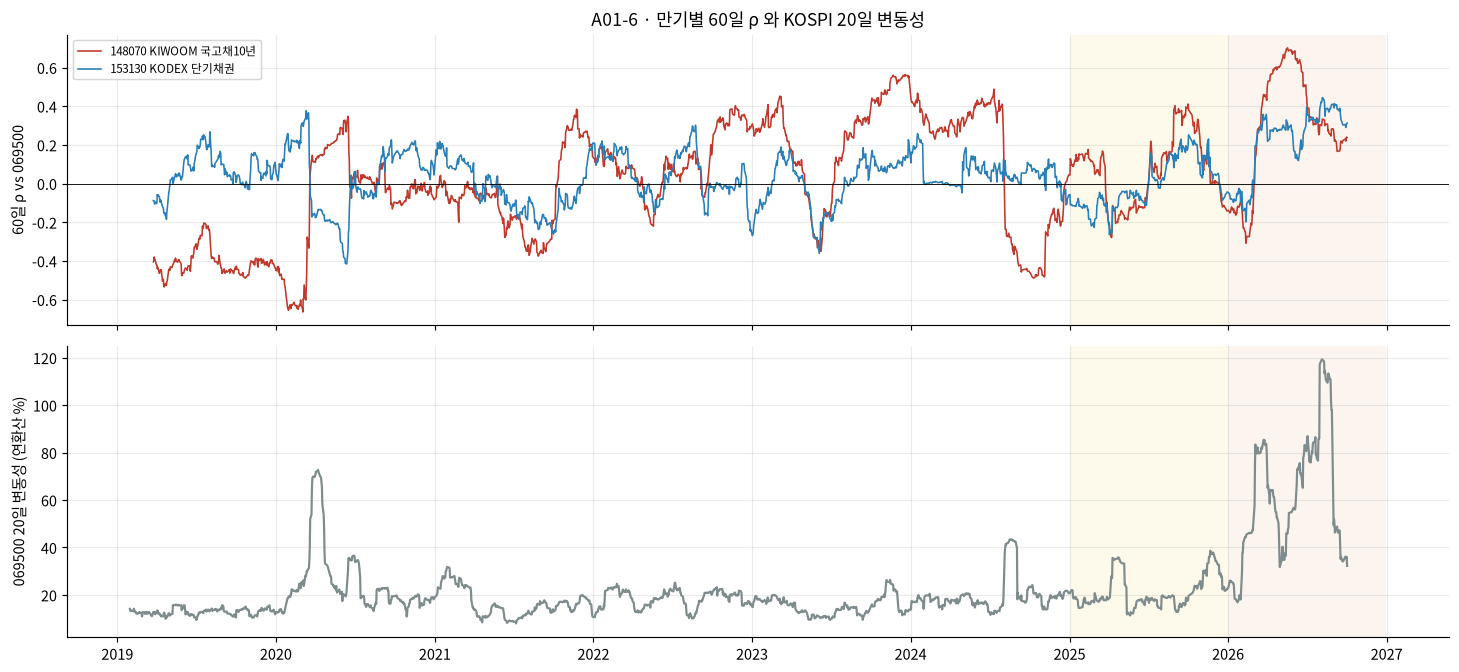

,r148,r153
vol,,
vol Q1(저),-0.174,-0.000
Q2,0.176,0.064
Q3,0.086,0.037
vol Q4(고),0.087,0.071


corr(ρ148, ρ153) 60일: 0.204


,dev_2019_2024,val_2025,holdout_2026
148070,-0.002,0.063,0.300
153130,0.025,-0.008,0.223


In [12]:
vol20 = r[REF].rolling(20).std() * np.sqrt(252)
fig, ax = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
ax[0].plot(rhos["148070"][60].index, rhos["148070"][60], color="#c0392b", lw=1.1, label=LAB["148070"])
ax[0].plot(rhos["153130"][60].index, rhos["153130"][60], color="#2980b9", lw=1.1, label=LAB["153130"])
ax[0].axhline(0, c="k", lw=.6); ax[0].set_ylabel("60일 ρ vs 069500"); ax[0].legend(fontsize=8)
ax[0].set_title("A01-6 · 만기별 60일 ρ 와 KOSPI 20일 변동성")
ax[1].plot(vol20.index, vol20 * 100, color="#7f8c8d"); ax[1].set_ylabel("069500 20일 변동성 (연환산 %)")
for a in ax: V.shade_periods(a)
fig.tight_layout(); savefig(fig, "06_maturity_vol"); plt.show()
both = pd.concat({"r148": rhos["148070"][60], "r153": rhos["153130"][60], "vol": vol20.rolling(60).mean()}, axis=1).dropna()
q = pd.qcut(both["vol"], 4, labels=["vol Q1(저)", "Q2", "Q3", "vol Q4(고)"])
bytab = both.groupby(q, observed=True)[["r148", "r153"]].mean()
display(bytab.round(3))
print("corr(ρ148, ρ153) 60일:", round(both.r148.corr(both.r153), 3))
per = RC.period_of(r.index)
p26 = pd.DataFrame({t: {k: rhos[t][60][per == k].mean() for k in RC.PERIODS} for t in ["148070", "153130"]}).T
display(p26.round(3))
assert p26.loc["148070", "holdout_2026"] > 0.25 and abs(both.r148.corr(both.r153) - 0.204) < 5e-3 and bytab.iloc[0, 0] < -0.15

### 해석
- **만기 차이**: 두 채권의 60일 ρ 끼리의 상관은 0.20 — 같은 방향으로 움직이는 경향은 있지만 약하다. 148070 은 ±0.6 대의 뚜렷한 국면을 보이는 반면 153130 은 대부분 ±0.25 안이다.
  단기채는 금리 변동 노출이 작아 KOSPI 와 공유할 정보 자체가 적다 → 관계가 '다르게' 보이는 것이 아니라 '거의 없다'.
- **변동성 국면**: KOSPI 변동성 최저 사분위에서 148070 평균 ρ 는 **−0.17**, Q2~Q4 는 +0.09~+0.18 이다(153130 은 0.00 → 0.07). 고변동 국면의 상관은 소수의 큰 날이 결정한다(§6) — 국면 효과와 기계적 효과가 섞여 있다.
- **2026 (관찰 구간, blind holdout 아님)**: 148070 60일 ρ 평균 0.30, 153130 0.22 — 2019-24(−0.00, 0.03)와 뚜렷이 다르다. 같은 해 KOSPI 변동성은
  2019-25 대비 약 3배. 2026 의 양(+)의 상관이 '새 관계'인지 '고변동 국면의 동반 하락·반등'인지 이 데이터만으로 구분할 수 없다.

> **재구성 질문** — 2026 의 양(+)의 주식–채권 상관을 경제적 국면 변화라고 결론 내리기 전에 확인해야 할 세 가지는?

## 10. A01 결론과 한계

| 질문 | 답 (근거) |
|---|---|
| 국고채10년–KOSPI200 상관은 안정적인가? | **아니다.** 연도별 −0.40(2019) ~ +0.37(2026). 60일 ρ 평균 0.037, 시간의 51% 가 ±0.25 안 (§2·§4) |
| 창에 따라 다른가? | 교차 55/45/41(30/60/120일), C3 21/13/7. 긴 창은 늦고 평균화 (§4·§5) |
| 0선 교차 = 구조 변화? | **아니다.** 독립 난수도 수십 번 교차(§3). 교차의 44% 는 하루 수익률이 만든 것(§6). C3 로 걸러야 후보가 됨 |
| 단기채 0 수익률 영향? | 교차 137 → 97 (0→NaN), n_eff 30 → 25.0. spike 2일이 ρ 를 0.32 이동 (§7) |
| 대조 ETF | 102110 기준 결과 거의 동일 — 독립 증거 아님 (§8) |

**한계**: 근사 오차대는 독립성 검정이 아니다. band·persist 는 선택값이다(A02 에서 민감도). 2026 은 이미 탐색된 구간이다. 가격 조정 여부 미확정(A00 §5).
**다음**: A012 — 같은 틀로 해외주식·원자재·FX·코스닥. A02 — 이 후보들이 가격 사건과 시간적으로 가까운가.